# Dependency graph and reference path

Load the validated `real_v1` graph, inspect its weights and plot the ideal response to a 20% WTI increase. The real graph and processed market inputs must be prepared before running this notebook.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from marketsim.data import api
from marketsim.graph import load_graph
from marketsim.graph.reference import reference_path
from marketsim.graph.scenarios import build_real_2024_2025

graph = load_graph("real_v1")
graph.validate()
print(f"Companies: {len(graph.companies())}; full spectral radius: {graph.spectral_radius('full'):.4f}")

Companies: 18; full spectral radius: 0.0000


## Graph and edge-weight table

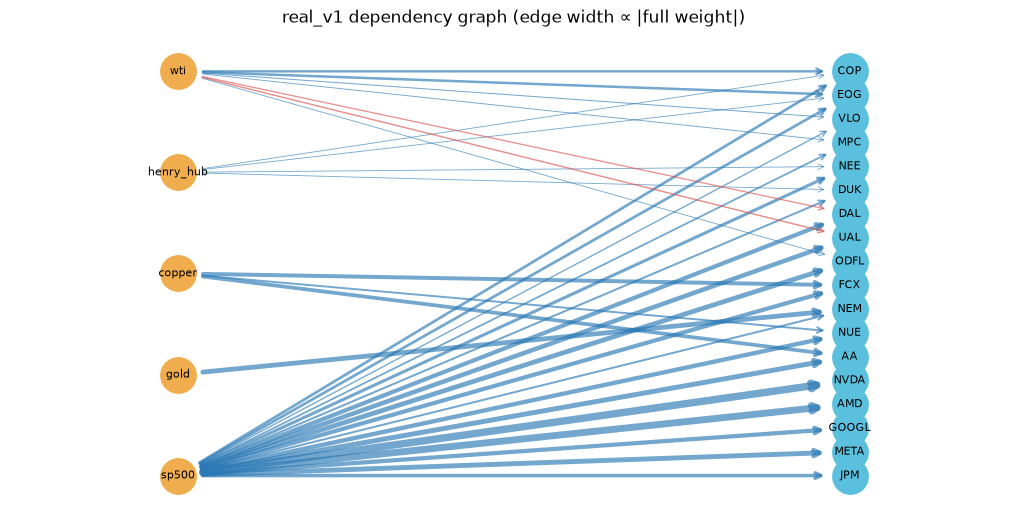

,parent,child,w_direct,w_full,t_stat_direct,t_stat_full,source,justification
0,wti,COP,0.514614,0.514614,20.2979,20.2979,commodity,Crude oil exploration and production revenue d...
1,henry_hub,COP,0.005580,0.005580,0.7713,0.7713,commodity,Natural gas co-production revenue of upstream ...
2,sp500,COP,0.616778,0.616778,10.8865,10.8865,index,Common US equity market factor (S&P 500)
3,wti,EOG,0.552229,0.552229,18.8850,18.8850,commodity,Crude oil exploration and production revenue d...
4,henry_hub,EOG,0.004285,0.004285,0.5137,0.5137,commodity,Natural gas co-production revenue of upstream ...
5,sp500,EOG,0.620723,0.620723,9.4992,9.4992,index,Common US equity market factor (S&P 500)
6,wti,VLO,0.429949,0.053988,14.1257,1.7470,commodity,Crude oil is the primary feedstock of petroleu...
7,sp500,VLO,0.602782,0.158980,8.8595,2.6853,index,Common US equity market factor (S&P 500)
8,COP,VLO,NaN,0.538254,NaN,9.2814,bea,BEA 2023: petroleum refining (324) spends 50.8...
9,EOG,VLO,NaN,0.177971,NaN,3.5387,bea,BEA 2023: petroleum refining (324) spends 50.8...


In [2]:
external_nodes = graph.externals()
company_nodes = graph.companies()
positions = {}
for i, node in enumerate(external_nodes):
    positions[node] = (0.0, 1.0 - i / max(len(external_nodes) - 1, 1))
for i, node in enumerate(company_nodes):
    positions[node] = (1.0, 1.0 - i / max(len(company_nodes) - 1, 1))

fig, ax = plt.subplots(figsize=(13, max(6, len(company_nodes) * 0.35)))
for edge in graph.edges:
    start, end = positions[edge.parent], positions[edge.child]
    weight = edge.w_full if edge.w_full is not None else edge.w_direct
    ax.annotate(
        "", xy=end, xytext=start,
        arrowprops={"arrowstyle": "->", "color": "#2878b5" if weight >= 0 else "#d9534f",
                    "lw": 0.6 + 2.2 * abs(weight), "alpha": 0.65, "shrinkA": 18, "shrinkB": 18},
    )
for node, (x, y) in positions.items():
    is_external = node in external_nodes
    ax.scatter(x, y, s=650, color="#f0ad4e" if is_external else "#5bc0de", zorder=3)
    ax.text(x, y, node, ha="center", va="center", fontsize=8, zorder=4)
ax.set_xlim(-0.25, 1.25)
ax.set_ylim(-0.1, 1.1)
ax.axis("off")
ax.set_title("real_v1 dependency graph (edge width ∝ |full weight|)")
plt.show()

weights = pd.DataFrame([
    {"parent": e.parent, "child": e.child, "w_direct": e.w_direct,
     "w_full": e.w_full, "t_stat_direct": e.t_stat_direct,
     "t_stat_full": e.t_stat_full, "source": e.source,
     "justification": e.justification}
    for e in graph.edges
])
display(weights)

## Reference wave: WTI +20%, all other external signals flat

This is an idealized shock, not a simulated market outcome. The rise starts at session 5 to match the `oil_shock` fixture.

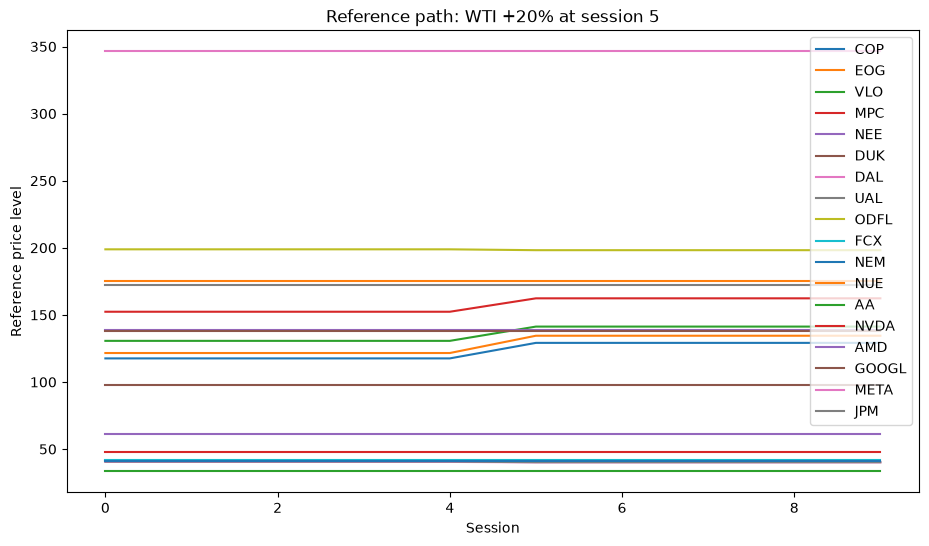

In [3]:
shock = pd.DataFrame(
    {node: np.full(10, 100.0) for node in external_nodes},
    index=pd.Index(range(10), name="session"),
)
if "wti" not in shock.columns:
    raise ValueError("real_v1 must include the wti external node")
shock.loc[5:, "wti"] = 120.0
reference = reference_path(graph, shock, mode="full")
ax = reference.plot(figsize=(11, 6), title="Reference path: WTI +20% at session 5")
ax.set_ylabel("Reference price level")
ax.set_xlabel("Session")
plt.show()

## Real 2024-2025 external scenario

Run this cell after the cleaned daily data are available. It writes the `EXTERNAL`-validated parquet via the data API.

In [4]:
path = build_real_2024_2025()
real = api.load_external("real_2024_2025")
print(f"{path.name}: {len(real)} sessions, {real['date'].min().date()} .. {real['date'].max().date()}")
real.head()

external_real_2024_2025.parquet: 502 sessions, 2024-01-02 .. 2025-12-31


,date,wti,henry_hub,copper,gold,sp500
session,,,,,,
0,2024-01-02,70.62,2.56,3.8690,2073.399902,4742.83
1,2024-01-03,72.97,2.57,3.8475,2042.800049,4704.81
2,2024-01-04,72.38,2.83,3.8310,2050.000000,4688.68
3,2024-01-05,74.00,2.75,3.7945,2049.800049,4697.24
4,2024-01-08,71.06,2.72,3.7995,2033.500000,4763.54
